# SoilGrids — Raw Store vs Aligned Source

Exploration view of the first **Source** of the Bandstack, before and
after its single warp onto the common grid. Every check is shown
**side-by-side**: raw (native grid) next to aligned (common grid).

- **Scope**: 0–30 cm depth slice, mean statistic — 10 properties × 3 depths
  plus `ocs` (0–30 cm only) = **31 layers**, the same inventory as
  `bandstack.sources.soilgrids`
- **Raw Store**: `data/raw/soilgrids/`, fetched and verified by the pipeline
  (`python -m bandstack`) — ISRIC filenames, values as published int16
  (decode only for display/analysis)
- **Raw native grid**: Interrupted Goode Homolosine on a **sphere**
  (R = 6371000 m), 250 m cells. No alignment, no resampling here
- **Aligned Source**: `data/aligned/soilgrids/soilgrids_lambert72_200m.tif` —
  one multi-band float32 GeoTIFF on the common **Lambert 72** grid
  (EPSG:31370, 200 m cells), decoded physical units, NaN nodata, Study
  Area mask applied at align time (`bandstack.align.warp_band`)
- **Unmasked rectangle** (raw only): raw files include land beyond the
  Study Area (Brussels, Zeeland, ...); the mask is applied per grid in the
  statistics and plots below — at display time for raw, already at align
  time for aligned

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from bandstack.grid import GridSpec, study_area_mask
from bandstack.sources.soilgrids import (
    CITIES,
    DEPTHS,
    LAYERS,
    UNITS,
    decode_factor,
)
from bandstack.sources.soilgrids import (
    CRS_IGH as SG_CRS,
)
from bandstack.sources.soilgrids import (
    NODATA as SG_NODATA,
)

RAW_DIR = ROOT / "data" / "raw" / "soilgrids"
ALIGNED_DIR = ROOT / "data" / "aligned" / "soilgrids"
ALIGNED_TIF = ALIGNED_DIR / "soilgrids_lambert72_200m.tif"
ALIGNED_META = ALIGNED_DIR / "_metadata.json"
GISCO_DIR = ROOT / "data" / "raw" / "gisco"
NUTS_ID = "BE2"

with rasterio.open(ALIGNED_TIF) as src:
    ALIGNED_CRS = src.crs
    ALIGNED_GRID = GridSpec(
        crs=src.crs, transform=src.transform, width=src.width, height=src.height
    )
    BAND = {d: i for i, d in enumerate(src.descriptions, start=1)}

assert set(BAND) == set(LAYERS), "aligned band descriptions must match LAYERS"

print(f"{len(LAYERS)} layers (0–30 cm inventory, shared with the bandstack package)")
print("raw native grid:", SG_CRS.to_proj4())
print(
    f"aligned grid: {ALIGNED_CRS.to_string()}, {ALIGNED_GRID.res:.0f} m cells, "
    f"{ALIGNED_GRID.width}×{ALIGNED_GRID.height}"
)
print(f"aligned bands: {len(BAND)}, decoded float32, NaN nodata")

31 layers (0–30 cm inventory, shared with the bandstack package)
raw native grid: +proj=igh +lon_0=0 +x_0=0 +y_0=0 +R=6371000 +units=m +no_defs=True
aligned grid: EPSG:31370, 200 m cells, 1195×465
aligned bands: 31, decoded float32, NaN nodata


## Study Area polygon

`BE2` = **Flemish Region** (Brussels is its own NUTS region `BE1` and
excluded). The cached polygon under `data/raw/gisco/`
is the canonical mask geometry, consumed by `bandstack.grid`; here it is
just reprojected to each store's CRS for display. The polygon —
never the raster — moves between CRSs.

Vlaams Gewest — MultiPolygon
bounds (IGH m): [1277527 5602268 1529240 5686979]
bounds (L72 m): [ 22307 153118 258821 243997]


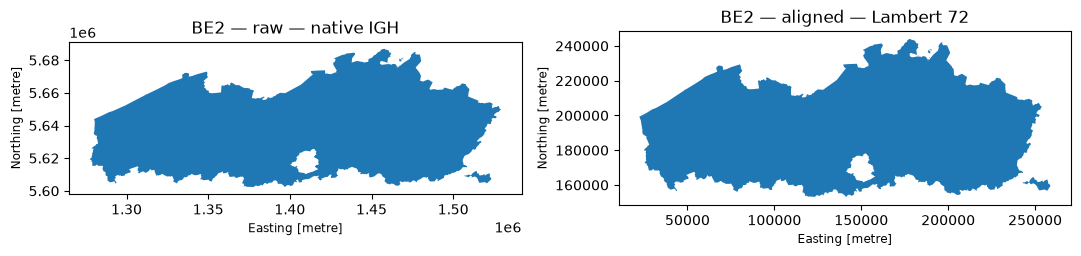

In [2]:
be2_path = GISCO_DIR / "be2_flemish_region_4326.geojson"
be2_igh = gpd.read_file(be2_path).to_crs(SG_CRS)
be2_l72 = gpd.read_file(be2_path).to_crs(ALIGNED_CRS)
print(f"{be2_igh.iloc[0]['NAME_LATN']} — {be2_igh.geometry.iloc[0].geom_type}")
print("bounds (IGH m):", np.round(be2_igh.total_bounds).astype(int))
print("bounds (L72 m):", np.round(be2_l72.total_bounds).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for ax, gdf, label in [
    (axes[0], be2_igh, "raw — native IGH"),
    (axes[1], be2_l72, "aligned — Lambert 72"),
]:
    gdf.plot(ax=ax)
    ax.set_title(f"{NUTS_ID} — {label}")
plt.tight_layout()
plt.show()

## The two stores

The fetch is owned by the pipeline (`python -m bandstack`,
`bandstack.sources.soilgrids.fetch_raw`): windowed reads from the
published COG VRTs, one window per layer on that layer's *own* VRT
transform — the published VRTs form two grid families whose origins sit
750 m (3 px) apart — into the unmasked target-grid
rectangle, verified by the fetch gate and recorded in the
Provenance Record (`_metadata.json`).

The align is owned by the pipeline too (`bandstack.align.warp_band`):
exactly **one bilinear warp per layer** from the native IGH grid onto the
common Lambert 72 grid, the decode factor applied *after* the warp
(linear, exact under bilinear), the Study Area mask applied *after* the
warp — float32 decoded values, NaN outside the mask. 

In [3]:
rows = []
families = {}

with rasterio.open(ALIGNED_TIF) as aligned_src:
    inside_aligned = study_area_mask(ALIGNED_GRID)
    for layer in LAYERS:
        with rasterio.open(RAW_DIR / f"{layer}.tif") as src:
            arr = src.read(1)
            inside = study_area_mask(
                GridSpec(crs=SG_CRS, transform=src.transform, width=src.width, height=src.height)
            )
            families.setdefault(src.transform, layer)

        factor = decode_factor(layer)
        valid = arr != SG_NODATA
        raw_vals = arr[valid & inside] / factor

        band = aligned_src.read(BAND[layer])
        aln_valid = np.isfinite(band)
        aln_vals = band[aln_valid & inside_aligned]

        rows.append(
            {
                ("raw", "valid_frac_inside"): valid[inside].sum() / inside.sum(),
                ("raw", "min"): float(raw_vals.min()),
                ("raw", "max"): float(raw_vals.max()),
                ("raw", "mean"): float(raw_vals.mean()),
                ("aligned", "valid_frac_inside"): aln_valid[inside_aligned].sum()
                / inside_aligned.sum(),
                ("aligned", "min"): float(aln_vals.min()),
                ("aligned", "max"): float(aln_vals.max()),
                ("aligned", "mean"): float(aln_vals.mean()),
                ("unit", ""): UNITS[layer.split("_", 1)[0]][1],
            }
        )

stats_df = pd.DataFrame(rows, index=pd.Index(LAYERS, name="layer"))
stats_df.columns = pd.MultiIndex.from_tuples(stats_df.columns)

sidecar = json.loads(ALIGNED_META.read_text())["bands"]
d_valid = max(
    abs(r[("aligned", "valid_frac_inside")] - (1 - b["nan_inside_frac"]))
    for r, b in zip(rows, sidecar, strict=True)
)
d_min = max(abs(r[("aligned", "min")] - b["min"]) for r, b in zip(rows, sidecar, strict=True))
d_max = max(abs(r[("aligned", "max")] - b["max"]) for r, b in zip(rows, sidecar, strict=True))

print(f"{len(families)} distinct stored window(s) (raw):")
for t, layer in families.items():
    print(f"  origin ({t.c:,.0f}, {t.f:,.0f}) — e.g. {layer}")
print(f"sidecar cross-check: max |Δvalid| {d_valid:.2e}, |Δmin| {d_min:.2e}, |Δmax| {d_max:.2e}")

1 distinct stored window(s) (raw):
  origin (1,267,500, 5,688,750) — e.g. bdod_0-5cm_mean
sidecar cross-check: max |Δvalid| 0.00e+00, |Δmin| 0.00e+00, |Δmax| 0.00e+00


## Sanity checks

1. Per-layer value ranges, valid fractions and means — raw (decoded,
   inside the Study Area, native grid) side-by-side with aligned, one row
   per layer
2. Cities pH from both stores: a *coarse plausibility* check against
   regional pH(H2O) ranges. It catches gross errors — placement, decode,
   masking — but not small misregistration. Brussels has raw data but NaN
   when aligned: it lies inside the raw store's unmasked rectangle and is
   excluded at align time, not fetch time
3. Texture closure: clay + silt + sand ≈ 1000 g/kg per depth, in both
   stores
4. Eyeball maps of every property — the ten depth-sliced properties
   at 0–5 cm plus `ocs` at its only published depth, 0–30 cm — raw on
   IGH next to aligned on Lambert 72, one shared color scale per row
   so the colors are honestly comparable

In [4]:
stats_df.style.format(
    {
        ("raw", "valid_frac_inside"): "{:.1%}",
        ("aligned", "valid_frac_inside"): "{:.1%}",
        ("raw", "min"): "{:,.2f}",
        ("raw", "max"): "{:,.2f}",
        ("raw", "mean"): "{:,.2f}",
        ("aligned", "min"): "{:,.2f}",
        ("aligned", "max"): "{:,.2f}",
        ("aligned", "mean"): "{:,.2f}",
    }
)

Around 18% of the Study Area is NaN (no data available): SoilGrids
masks waterways and hardened surfaces — these are Published Gaps, and
re-fetching never fills them. The aligned valid fraction tracks the raw
one closely; the small drift is the warp's bilinear handling of gap
edges plus the `all_touched` mask on the coarser grid, not new gaps.

In [5]:
def local_median(src, x, y, band=1, half=1):
    r, c = src.index(x, y)
    w = Window(c - half, r - half, 2 * half + 1, 2 * half + 1)
    a = src.read(band, window=w).astype("float64")
    a[(a == SG_NODATA) | ~np.isfinite(a)] = np.nan
    v = a[np.isfinite(a)]
    return float(np.median(v)) if v.size else np.nan


lons = [lon for lon, _ in CITIES.values()]
lats = [lat for _, lat in CITIES.values()]
xs_igh, ys_igh = warp_transform("EPSG:4326", SG_CRS, lons, lats)
xs_l72, ys_l72 = warp_transform("EPSG:4326", ALIGNED_CRS, lons, lats)

ph_factor = UNITS["phh2o"][0]
ph_rows = []
with (
    rasterio.open(RAW_DIR / "phh2o_0-5cm_mean.tif") as raw_src,
    rasterio.open(ALIGNED_TIF) as aln_src,
):
    for (name, _), xi, yi, xa, ya in zip(
        CITIES.items(), xs_igh, ys_igh, xs_l72, ys_l72, strict=True
    ):
        raw = local_median(raw_src, xi, yi) / ph_factor  # stored int16 → decode
        aln = local_median(aln_src, xa, ya, band=BAND["phh2o_0-5cm_mean"])  # already decoded
        ph_rows.append({"city": name, "raw (IGH)": raw, "aligned (L72)": aln, "Δ": aln - raw})
pd.DataFrame(ph_rows).set_index("city").round(2)

,raw (IGH),aligned (L72),Δ
city,,,
Brussels,5.0,NaN,NaN
Leuven,5.1,5.16,0.06
Ghent,5.7,5.65,-0.05
Antwerp,5.3,5.36,0.06
Bruges,5.9,5.88,-0.02
Hasselt,6.3,6.24,-0.06


No major outliers; |Δ| ≤ 0.06 pH, and the drift (200 m grid, bilinear
smoothing, 3×3 median windows) is the expected magnitude — the align
gate's own spot check (point interpolation) agrees within ±0.05.
Brussels is NaN in the aligned column by design: the city is outside
the Study Area (NUTS `BE1`) and the aligned store is masked at align
time; the raw store's unmasked rectangle still contains it.

In [6]:
def texture_dev(vals):
    ok = np.isfinite(vals["clay"]) & np.isfinite(vals["silt"]) & np.isfinite(vals["sand"])
    total = vals["clay"] + vals["silt"] + vals["sand"]
    dev = (total[ok] - 1000.0) / 10.0
    return int(ok.sum()), float(np.median(dev)), float(np.percentile(np.abs(dev), 95))


texture_rows = []
with rasterio.open(ALIGNED_TIF) as aln_src:
    for depth in DEPTHS:
        raw_fracs = {}
        aln_fracs = {}
        for prop in ("clay", "silt", "sand"):
            layer = f"{prop}_{depth}cm_mean"
            with rasterio.open(RAW_DIR / f"{layer}.tif") as src:
                a = src.read(1).astype("float64")
                a[a == SG_NODATA] = np.nan
                a /= decode_factor(layer)
                inside = study_area_mask(
                    GridSpec(
                        crs=SG_CRS, transform=src.transform, width=src.width, height=src.height
                    )
                )
                a[~inside] = np.nan
                raw_fracs[prop] = a
            aln_fracs[prop] = aln_src.read(BAND[layer]).astype("float64")
        raw_n, raw_med, raw_p95 = texture_dev(raw_fracs)
        aln_n, aln_med, aln_p95 = texture_dev(aln_fracs)
        texture_rows.append(
            {
                "depth_cm": depth,
                ("raw", "n_px"): raw_n,
                ("raw", "median_dev_pct"): raw_med,
                ("raw", "p95_abs_dev_pct"): raw_p95,
                ("aligned", "n_px"): aln_n,
                ("aligned", "median_dev_pct"): aln_med,
                ("aligned", "p95_abs_dev_pct"): aln_p95,
            }
        )
texture_df = pd.DataFrame(texture_rows).set_index("depth_cm")
texture_df.columns = pd.MultiIndex.from_tuples(texture_df.columns)
texture_df

raw                                aligned                 \
            n_px median_dev_pct p95_abs_dev_pct    n_px median_dev_pct   
depth_cm                                                                 
0-5       180600            0.0             0.1  282448            0.0   
5-15      180600            0.0             0.1  282448            0.0   
15-30     180600            0.0             0.1  282448            0.0   

                          
         p95_abs_dev_pct  
depth_cm                  
0-5             0.079624  
5-15            0.079368  
15-30           0.079806

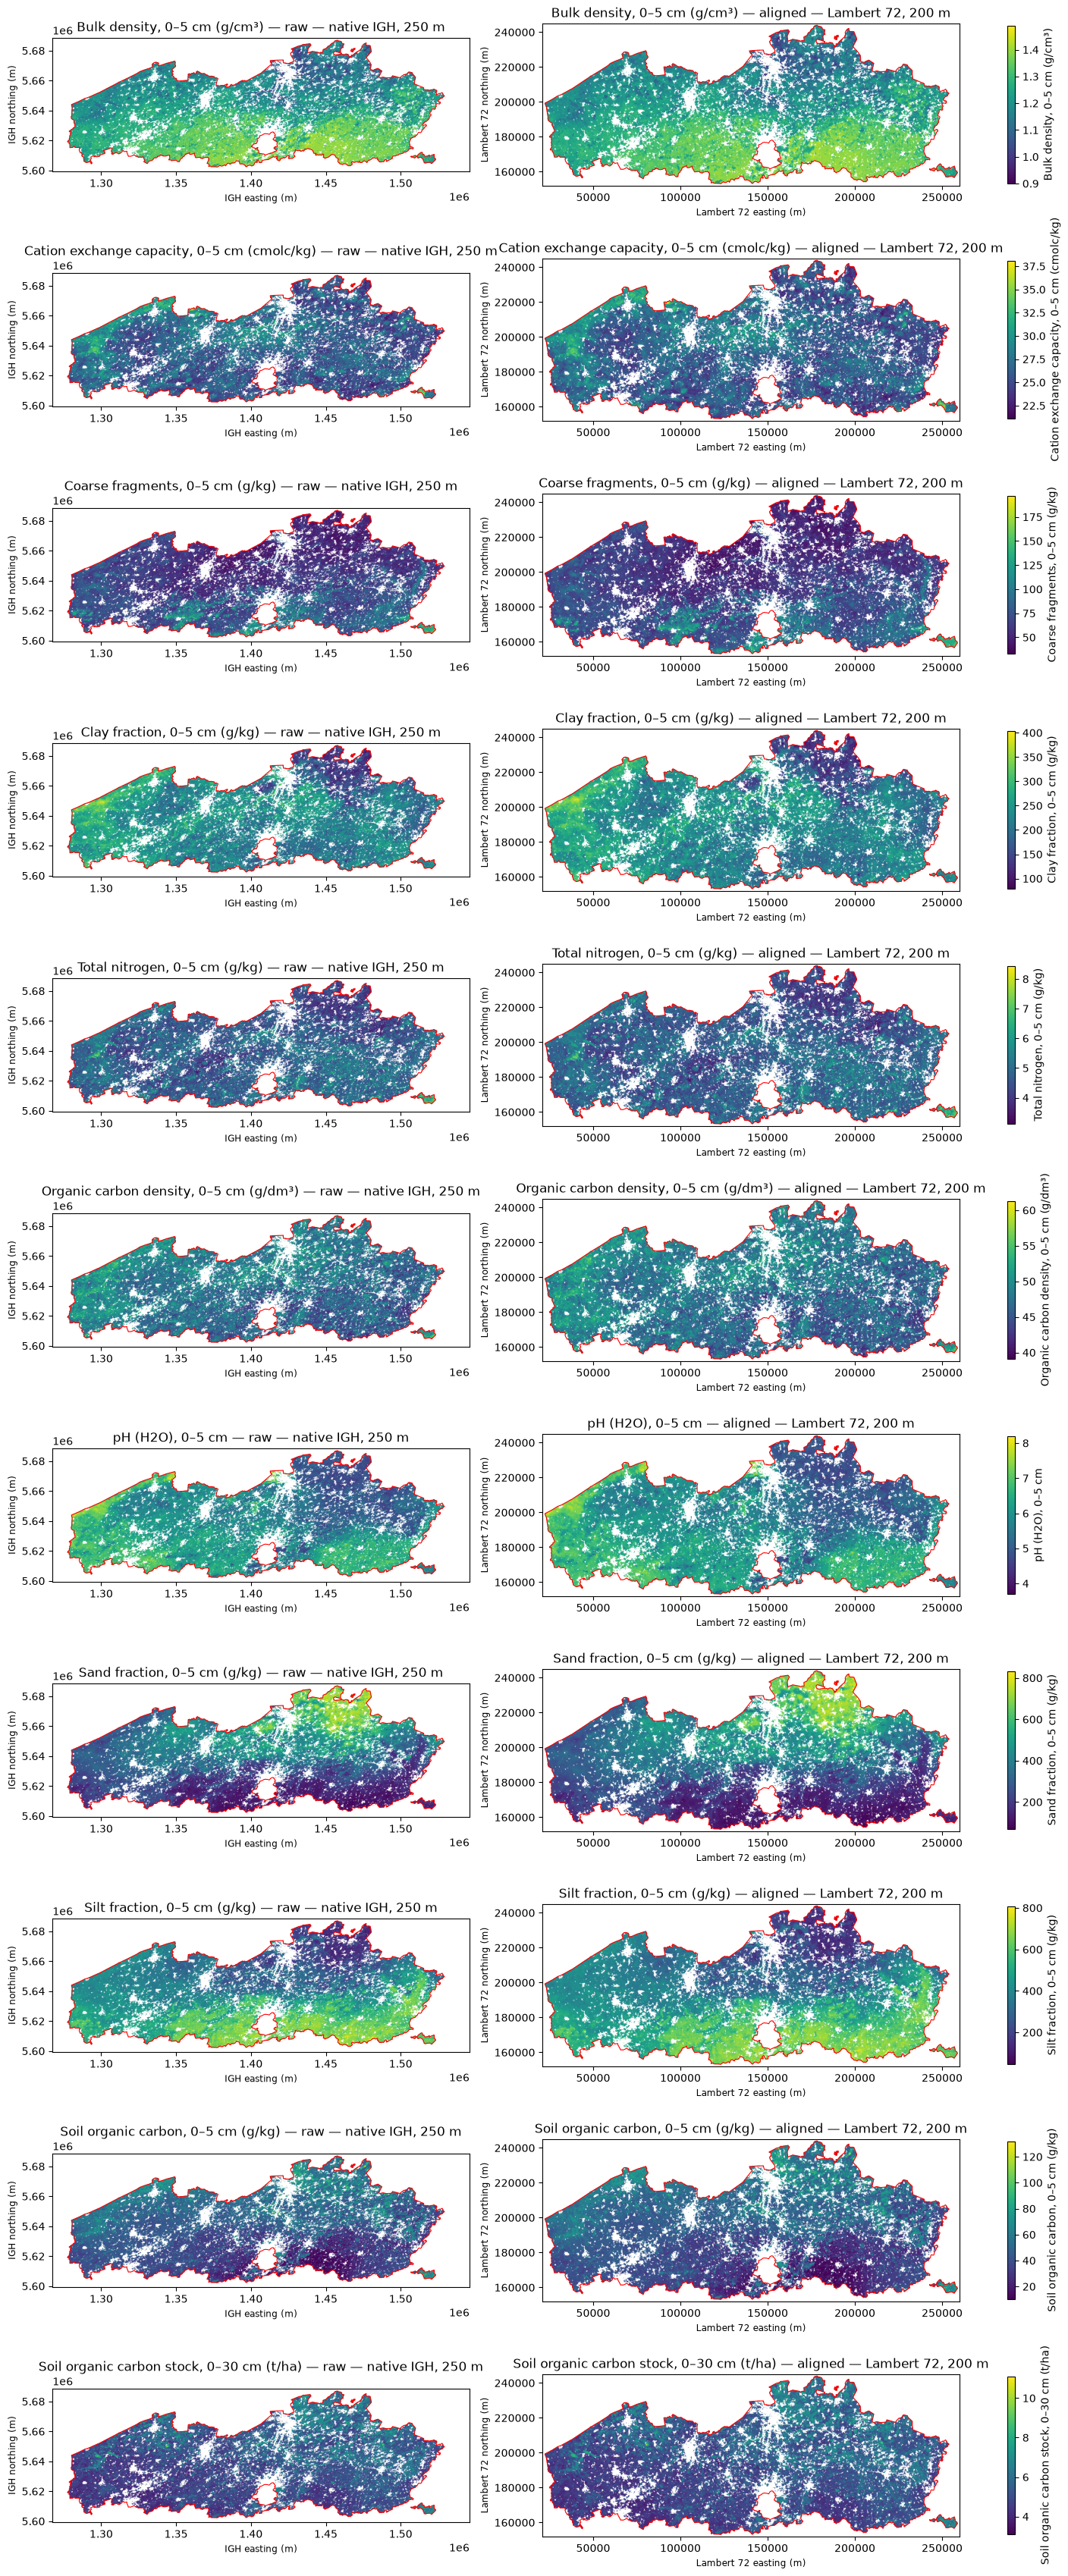

In [7]:
panels = [
    ("bdod_0-5cm_mean", "bdod", "Bulk density, 0–5 cm (g/cm³)"),
    ("cec_0-5cm_mean", "cec", "Cation exchange capacity, 0–5 cm (cmolc/kg)"),
    ("cfvo_0-5cm_mean", "cfvo", "Coarse fragments, 0–5 cm (g/kg)"),
    ("clay_0-5cm_mean", "clay", "Clay fraction, 0–5 cm (g/kg)"),
    ("nitrogen_0-5cm_mean", "nitrogen", "Total nitrogen, 0–5 cm (g/kg)"),
    ("ocd_0-5cm_mean", "ocd", "Organic carbon density, 0–5 cm (g/dm³)"),
    ("phh2o_0-5cm_mean", "phh2o", "pH (H2O), 0–5 cm"),
    ("sand_0-5cm_mean", "sand", "Sand fraction, 0–5 cm (g/kg)"),
    ("silt_0-5cm_mean", "silt", "Silt fraction, 0–5 cm (g/kg)"),
    ("soc_0-5cm_mean", "soc", "Soil organic carbon, 0–5 cm (g/kg)"),
    ("ocs_0-30cm_mean", "ocs", "Soil organic carbon stock, 0–30 cm (t/ha)"),
]
fig, axes = plt.subplots(len(panels), 2, figsize=(14, 3.1 * len(panels)), layout="constrained")
with rasterio.open(ALIGNED_TIF) as aln_src:
    for row, (layer, prop, title) in zip(axes, panels, strict=True):
        factor = UNITS[prop][0]
        with rasterio.open(RAW_DIR / f"{layer}.tif") as src:
            raw = np.ma.filled(src.read(1, masked=True) / factor, np.nan)
            raw_extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
            inside = study_area_mask(
                GridSpec(crs=SG_CRS, transform=src.transform, width=src.width, height=src.height)
            )
        raw[~inside] = np.nan

        aln = aln_src.read(BAND[layer])
        aln_extent = (
            aln_src.bounds.left,
            aln_src.bounds.right,
            aln_src.bounds.bottom,
            aln_src.bounds.top,
        )

        finite = np.concatenate([raw[np.isfinite(raw)], aln[np.isfinite(aln)]])
        vmin, vmax = float(finite.min()), float(finite.max())

        for ax, data, extent, gdf, label, xl, yl in [
            (
                row[0],
                raw,
                raw_extent,
                be2_igh,
                "raw — native IGH, 250 m",
                "IGH easting (m)",
                "IGH northing (m)",
            ),
            (
                row[1],
                aln,
                aln_extent,
                be2_l72,
                "aligned — Lambert 72, 200 m",
                "Lambert 72 easting (m)",
                "Lambert 72 northing (m)",
            ),
        ]:
            im = ax.imshow(data, extent=extent, cmap="viridis", vmin=vmin, vmax=vmax)
            gdf.boundary.plot(ax=ax, color="red", linewidth=0.8)
            ax.set_title(f"{title} — {label}")
            ax.set_xlabel(xl)
            ax.set_ylabel(yl)
        fig.colorbar(im, ax=list(row), shrink=0.7, label=title)
plt.show()